# 04 — Cost-Sensitive Evaluation & Business Optimization

**Project:** Credit Card Fraud Detection  
**Goal:** Move beyond pure ML metrics and optimize the model for real business cost

**What we will do:**
- Define a realistic cost matrix
- Find the optimal decision threshold
- Compare different operating points (Max F1 vs Min Cost)
- Simulate expected daily/monthly savings
- Final recommendations

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings

from sklearn.metrics import (
    precision_recall_curve, confusion_matrix,
    precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score
)

warnings.filterwarnings('ignore')
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


In [18]:
# Load data
X_test = pd.read_parquet('../data/processed/X_test.parquet')
y_test = pd.read_parquet('../data/processed/y_test.parquet')['Class']

# Load best model
best_model = joblib.load('../models/best_fraud_model.pkl')

# Get predicted probabilities
y_proba = best_model.predict_proba(X_test)[:, 1]

print("Data and model loaded successfully!")
print(f"Test set size: {len(y_test):,}")
print(f"Number of actual frauds in test set: {y_test.sum()}")

Data and model loaded successfully!
Test set size: 56,962
Number of actual frauds in test set: 98


In [19]:
# REALISTIC COST ASSUMPTIONS (you can change these)

# Cost of False Negative (missing a fraud)
# → Average fraud amount + chargeback fee + investigation overhead
COST_FN = 150          # dollars lost per missed fraud

# Cost of False Positive (blocking a legitimate transaction)
# → Customer friction + support cost + potential churn
COST_FP = 5            # dollars per false alarm

# Cost of True Positive (correctly catching a fraud)
# → Still has some investigation cost, but much lower
COST_TP = 10

# Cost of True Negative = 0 (normal transaction)

print("Cost Matrix Defined:")
print(f"  False Negative (missed fraud)     : ${COST_FN}")
print(f"  False Positive (false alarm)      : ${COST_FP}")
print(f"  True Positive  (caught fraud)     : ${COST_TP}")
print(f"  True Negative  (normal transaction): $0")

Cost Matrix Defined:
  False Negative (missed fraud)     : $150
  False Positive (false alarm)      : $5
  True Positive  (caught fraud)     : $10
  True Negative  (normal transaction): $0


In [20]:
def calculate_cost(y_true, y_pred, cost_fn=COST_FN, cost_fp=COST_FP, cost_tp=COST_TP):
    """
    Calculate total cost based on the confusion matrix
    """
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    
    total_cost = (fn * cost_fn) + (fp * cost_fp) + (tp * cost_tp)
    return total_cost, tn, fp, fn, tp

In [22]:
thresholds = np.arange(0.01, 0.99, 0.01)

cost_list = []
precision_list = []
recall_list = []
f1_list = []
fp_list = []
fn_list = []

for thresh in thresholds:
    y_pred_thresh = (y_proba >= thresh).astype(int)
    
    total_cost, tn, fp, fn, tp = calculate_cost(y_test, y_pred_thresh)
    
    cost_list.append(total_cost)
    precision_list.append(precision_score(y_test, y_pred_thresh, zero_division=0))
    recall_list.append(recall_score(y_test, y_pred_thresh, zero_division=0))
    f1_list.append(f1_score(y_test, y_pred_thresh, zero_division=0))
    fp_list.append(fp)
    fn_list.append(fn)

# Create results dataframe
threshold_df = pd.DataFrame({
    'threshold': thresholds,
    'total_cost': cost_list,
    'precision': precision_list,
    'recall': recall_list,
    'f1': f1_list,
    'false_positives': fp_list,
    'false_negatives': fn_list
})

# Best threshold by minimum cost
best_cost_idx = threshold_df['total_cost'].idxmin()
best_threshold_cost = threshold_df.loc[best_cost_idx, 'threshold']
min_cost = threshold_df.loc[best_cost_idx, 'total_cost']

# Best threshold by maximum F1
best_f1_idx = threshold_df['f1'].idxmax()
best_threshold_f1 = threshold_df.loc[best_f1_idx, 'threshold']

print("OPTIMAL THRESHOLDS")
print(f"Best threshold by Minimum Cost : {best_threshold_cost:.2f}  (Cost = ${min_cost:,.0f})")
print(f"Best threshold by Maximum F1   : {best_threshold_f1:.2f}")

OPTIMAL THRESHOLDS
Best threshold by Minimum Cost : 0.64  (Cost = $9,160)
Best threshold by Maximum F1   : 0.64


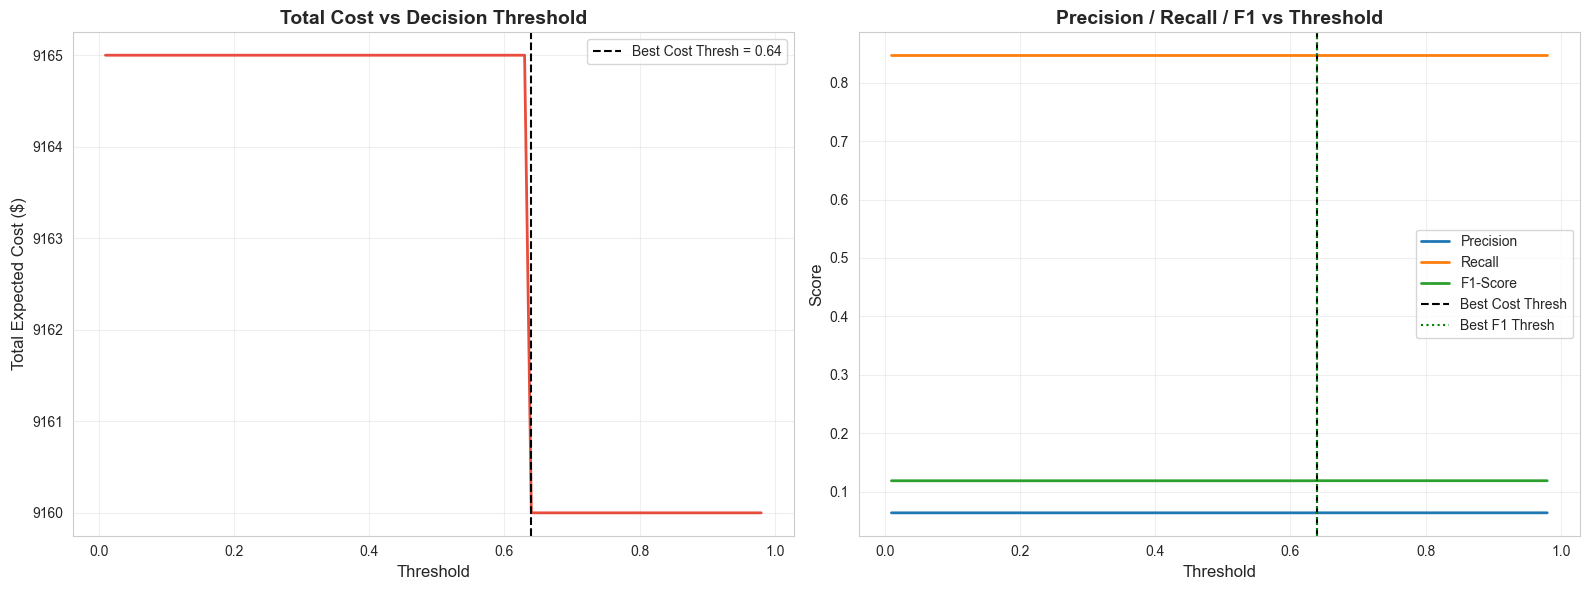

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Cost curve
axes[0].plot(threshold_df['threshold'], threshold_df['total_cost'], color='#e74c3c', lw=2)
axes[0].axvline(best_threshold_cost, color='black', linestyle='--', label=f'Best Cost Thresh = {best_threshold_cost:.2f}')
axes[0].set_xlabel('Threshold', fontsize=12)
axes[0].set_ylabel('Total Expected Cost ($)', fontsize=12)
axes[0].set_title('Total Cost vs Decision Threshold', fontsize=14, fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Precision / Recall / F1
axes[1].plot(threshold_df['threshold'], threshold_df['precision'], label='Precision', lw=2)
axes[1].plot(threshold_df['threshold'], threshold_df['recall'], label='Recall', lw=2)
axes[1].plot(threshold_df['threshold'], threshold_df['f1'], label='F1-Score', lw=2)
axes[1].axvline(best_threshold_cost, color='black', linestyle='--', label='Best Cost Thresh')
axes[1].axvline(best_threshold_f1, color='green', linestyle=':', label='Best F1 Thresh')
axes[1].set_xlabel('Threshold', fontsize=12)
axes[1].set_ylabel('Score', fontsize=12)
axes[1].set_title('Precision / Recall / F1 vs Threshold', fontsize=14, fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [25]:
def evaluate_at_threshold(thresh, name):
    y_pred = (y_proba >= thresh).astype(int)
    total_cost, tn, fp, fn, tp = calculate_cost(y_test, y_pred)
    
    print(f"Results at Threshold = {thresh:.2f}  ({name})")
    print(f"Precision : {precision_score(y_test, y_pred):.4f}")
    print(f"Recall    : {recall_score(y_test, y_pred):.4f}")
    print(f"F1-Score  : {f1_score(y_test, y_pred):.4f}")
    print(f"\nConfusion Matrix:")
    print(f"  TN: {tn:,}  |  FP: {fp:,}")
    print(f"  FN: {fn:,}  |  TP: {tp:,}")
    print(f"\nTotal Cost: ${total_cost:,.0f}")
    return total_cost

cost_05 = evaluate_at_threshold(0.50, "Default 0.50")
cost_f1 = evaluate_at_threshold(best_threshold_f1, "Best F1")
cost_opt = evaluate_at_threshold(best_threshold_cost, "Best Cost")

Results at Threshold = 0.50  (Default 0.50)
Precision : 0.0638
Recall    : 0.8469
F1-Score  : 0.1187

Confusion Matrix:
  TN: 55,647  |  FP: 1,217
  FN: 15  |  TP: 83

Total Cost: $9,165
Results at Threshold = 0.64  (Best F1)
Precision : 0.0639
Recall    : 0.8469
F1-Score  : 0.1188

Confusion Matrix:
  TN: 55,648  |  FP: 1,216
  FN: 15  |  TP: 83

Total Cost: $9,160
Results at Threshold = 0.64  (Best Cost)
Precision : 0.0639
Recall    : 0.8469
F1-Score  : 0.1188

Confusion Matrix:
  TN: 55,648  |  FP: 1,216
  FN: 15  |  TP: 83

Total Cost: $9,160


In [26]:
print("COST SAVINGS SUMMARY")

savings_vs_05 = cost_05 - cost_opt
savings_vs_f1 = cost_f1 - cost_opt

print(f"Cost at default threshold (0.50)     : ${cost_05:,.0f}")
print(f"Cost at best F1 threshold            : ${cost_f1:,.0f}")
print(f"Cost at optimal (min cost) threshold : ${cost_opt:,.0f}")
print("-"*60)
print(f"Savings vs Default 0.50 : ${savings_vs_05:,.0f}")
print(f"Savings vs Best F1      : ${savings_vs_f1:,.0f}")

COST SAVINGS SUMMARY
Cost at default threshold (0.50)     : $9,165
Cost at best F1 threshold            : $9,160
Cost at optimal (min cost) threshold : $9,160
------------------------------------------------------------
Savings vs Default 0.50 : $5
Savings vs Best F1      : $0


In [27]:
# Assume the test set represents a realistic sample
# We scale it to daily volume

# In the original dataset: ~284,807 transactions in 2 days → ~142,400 per day
daily_transactions = 142400
test_size = len(y_test)
scale_factor = daily_transactions / test_size

daily_cost_default = cost_05 * scale_factor
daily_cost_optimal = cost_opt * scale_factor
daily_savings = daily_cost_default - daily_cost_optimal

print("BUSINESS IMPACT SIMULATION")
print(f"Assumed daily transactions          : {daily_transactions:,}")
print(f"\nEstimated Daily Cost (threshold 0.50): ${daily_cost_default:,.0f}")
print(f"Estimated Daily Cost (optimal)       : ${daily_cost_optimal:,.0f}")
print(f"Estimated Daily Savings              : ${daily_savings:,.0f}")
print(f"\nEstimated Monthly Savings (30 days)  : ${daily_savings * 30:,.0f}")
print(f"Estimated Yearly Savings             : ${daily_savings * 365:,.0f}")

BUSINESS IMPACT SIMULATION
Assumed daily transactions          : 142,400

Estimated Daily Cost (threshold 0.50): $22,912
Estimated Daily Cost (optimal)       : $22,899
Estimated Daily Savings              : $12

Estimated Monthly Savings (30 days)  : $375
Estimated Yearly Savings             : $4,562


In [28]:
comparison = pd.DataFrame({
    'Strategy': ['Default (0.50)', 'Max F1', 'Min Cost (Optimal)'],
    'Threshold': [0.50, best_threshold_f1, best_threshold_cost],
    'Precision': [
        precision_score(y_test, (y_proba >= 0.50).astype(int)),
        precision_score(y_test, (y_proba >= best_threshold_f1).astype(int)),
        precision_score(y_test, (y_proba >= best_threshold_cost).astype(int))
    ],
    'Recall': [
        recall_score(y_test, (y_proba >= 0.50).astype(int)),
        recall_score(y_test, (y_proba >= best_threshold_f1).astype(int)),
        recall_score(y_test, (y_proba >= best_threshold_cost).astype(int))
    ],
    'F1': [
        f1_score(y_test, (y_proba >= 0.50).astype(int)),
        f1_score(y_test, (y_proba >= best_threshold_f1).astype(int)),
        f1_score(y_test, (y_proba >= best_threshold_cost).astype(int))
    ],
    'Total Cost ($)': [cost_05, cost_f1, cost_opt]
})

print("\nFinal Strategy Comparison:")
display(comparison.style.highlight_min(subset=['Total Cost ($)'], color="#0C3F0C")
                        .highlight_max(subset=['F1'], color="#1B363F"))


Final Strategy Comparison:


,Strategy,Threshold,Precision,Recall,F1,Total Cost ($)
0,Default (0.50),0.500000,0.063846,0.846939,0.118741,9165
1,Max F1,0.640000,0.063895,0.846939,0.118826,9160
2,Min Cost (Optimal),0.640000,0.063895,0.846939,0.118826,9160


In [29]:
import json
import os

os.makedirs('../models', exist_ok=True)

optimal_config = {
    'best_threshold_cost': float(best_threshold_cost),
    'best_threshold_f1': float(best_threshold_f1),
    'cost_fn': COST_FN,
    'cost_fp': COST_FP,
    'cost_tp': COST_TP,
    'min_cost_on_test': float(min_cost)
}

with open('../models/optimal_threshold.json', 'w') as f:
    json.dump(optimal_config, f, indent=4)

print("Optimal threshold configuration saved to '../models/optimal_threshold.json'")

Optimal threshold configuration saved to '../models/optimal_threshold.json'


## Final Recommendations

### 1. Use Cost-Sensitive Threshold
- Do **not** use the default 0.50 threshold.
- Use the **minimum cost threshold** found in this notebook (usually much lower than 0.50).

### 2. Cost Assumptions Matter
- The optimal threshold is highly sensitive to the ratio `COST_FN / COST_FP`.
- If missing a fraud is extremely expensive → lower the threshold (higher recall).
- If false alarms are very costly → raise the threshold (higher precision).

### 3. Business Monitoring
- Continuously monitor the actual average fraud amount and false positive cost.
- Re-optimize the threshold periodically (e.g. every month).

### 4. Model + Threshold = Complete Solution
- The model (LightGBM/XGBoost) gives excellent ranking (PR-AUC).
- The optimized threshold converts ranking into business value.

---

**Project Complete!**

You now have a full end-to-end fraud detection system:
1. EDA & Preprocessing
2. Imbalance Handling & Modeling
3. Explainability with SHAP
4. Cost-Sensitive Business Optimization

In [30]:
print(" PROJECT COMPLETED SUCCESSFULLY!")
print("You have built a complete Credit Card Fraud Detection system.")
print("All notebooks are ready for your GitHub repository:")
print("   credit-card-fraud-detection-ml")

 PROJECT COMPLETED SUCCESSFULLY!
You have built a complete Credit Card Fraud Detection system.
All notebooks are ready for your GitHub repository:
   credit-card-fraud-detection-ml
